# PCD Assignment 03
## Image Segmentation and Morphological Processing

**Nama:** Chelsea Christofera Antonioli Purnomo  
**NIM:** 25/558145/PA/23462  
**Mata Kuliah:** Digital Image Processing  
**Kelas:** KOM B

Tugas ini berfokus pada implementasi metode segmentasi citra dengan menggunakan Algoritma Python dan NumPy. Matplotlib digunakan untuk visualisasi, sedangkan PIL digunakan untuk membaca dan menyimpan gambar.

Tujuan dari tugas ini adalah:
1. Mengimplementasikan metode Otsu Thresholding untuk segmentasi citra.
2. Mengimplementasikan operasi morfologi secara mandiri, meliputi:
   - Dilation
   - Erosion
   - Opening
   - Closing
3. Membandingkan hasil segmentasi sebelum dan sesudah penerapan pengolahan morfologi.
4. Menganalisis pengaruh setiap operasi morfologi terhadap kualitas citra dan objek foreground.


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

import pandas as pd
from IPython.display import display

# Mengatur ukuran visualisasi
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['image.cmap'] = 'gray'

# Mengatur random seed agar hasil konsisten
np.random.seed(42)

print("Seluruh library berhasil diimpor!")

Seluruh library berhasil diimpor!


## 1. Persiapan Dataset

### Dataset 1: Gambar Koin
Gambar koin berisi beberapa objek berbentuk lingkaran dengan intensitas terang pada latar belakang gelap yang memiliki tekstur. Gambar ini digunakan sebagai dataset utama untuk menerapkan metode Otsu Thresholding.

### Dataset 2: Gambar Objek Biner
Gambar objek biner berisi objek foreground berwarna putih dan sejumlah noise berupa titik-titik putih kecil pada latar belakang hitam. Gambar ini digunakan untuk mengamati pengaruh operasi morfologi terhadap citra biner.

In [ ]:
print("Silakan unggah kedua gambar dataset:")
uploaded = files.upload()

# Membaca gambar yang telah diunggah
loaded_images = {}

for filename in uploaded.keys():
    image = Image.open(filename).convert('RGB')
    image_array = np.array(image)

    loaded_images[filename] = image_array

    print(
        f"{filename}: "
        f"{image_array.shape[1]} x {image_array.shape[0]}"
    )

# Mengidentifikasi gambar berdasarkan ukuran
# Gambar dengan ukuran lebih besar merupakan gambar koin.
# Gambar dengan ukuran lebih kecil merupakan gambar objek biner.

sorted_images = sorted(
    loaded_images.items(),
    key=lambda item: item[1].shape[0] * item[1].shape[1],
    reverse=True
)

coins_name, coins_rgb = sorted_images[0]
binary_name, binary_rgb = sorted_images[1]

print("\nDataset berhasil diidentifikasi!")
print("Gambar koin:", coins_name)
print("Gambar objek biner:", binary_name)

# Membuat direktori untuk menyimpan hasil
os.makedirs('/content/results/coins', exist_ok=True)
os.makedirs('/content/results/binary_objects', exist_ok=True)
os.makedirs('/content/analysis', exist_ok=True)

# Membuat direktori dataset
os.makedirs('/content/dataset', exist_ok=True)

# Menyimpan dataset menggunakan nama file standar
Image.fromarray(coins_rgb).save('/content/dataset/coins.png')
Image.fromarray(binary_rgb).save('/content/dataset/binary_objects.png')

print("\nDataset berhasil disimpan!")

Silakan unggah kedua gambar dataset:


Saving binary_objects.png to binary_objects.png
Saving coins.png to coins.png
binary_objects.png: 424 x 379
coins.png: 877 x 685

Dataset berhasil diidentifikasi!
Gambar koin: coins.png
Gambar objek biner: binary_objects.png

Dataset berhasil disimpan!


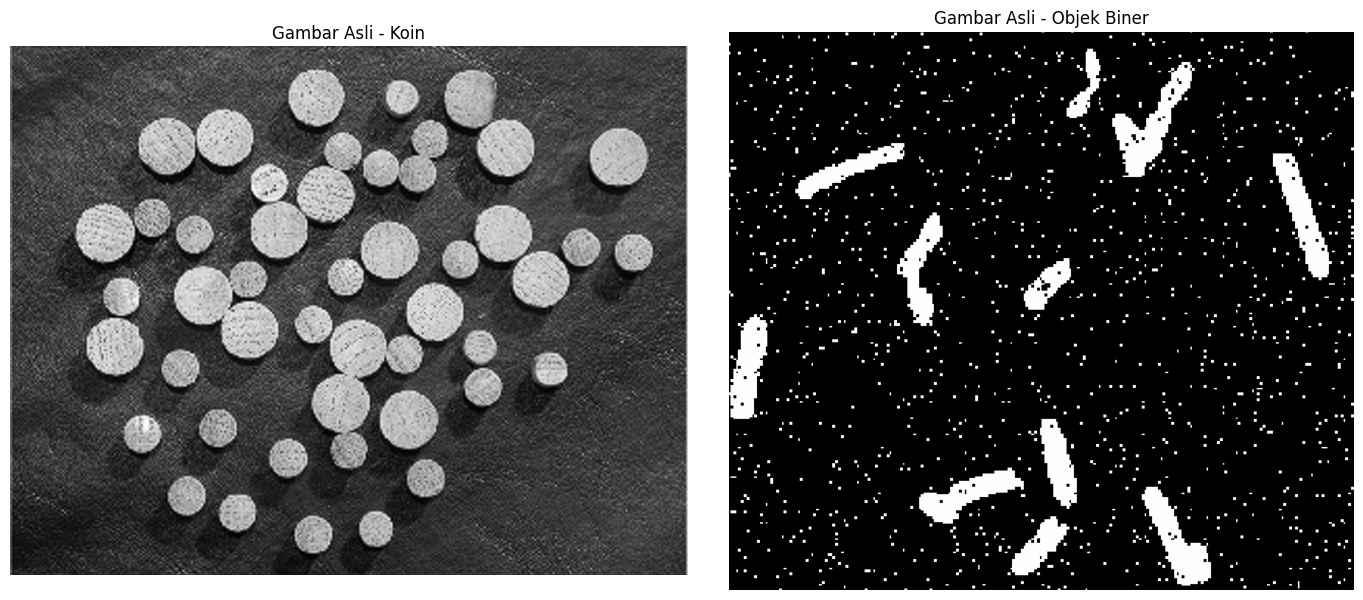

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(coins_rgb)
axes[0].set_title('Gambar Asli - Koin')
axes[0].axis('off')

axes[1].imshow(binary_rgb)
axes[1].set_title('Gambar Asli - Objek Biner')
axes[1].axis('off')

plt.tight_layout()

plt.savefig(
    '/content/results/original_images.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

## 2. Prapemrosesan Citra (Image Preprocessing)

### Konversi Grayscale
Sebelum menerapkan Otsu Thresholding, citra perlu dikonversi menjadi grayscale atau citra keabuan untuk menyederhanakan informasi citra menjadi satu kanal intensitas untuk analisis histogram dan segmentasi thresholding.

Konversi RGB menjadi grayscale dilakukan menggunakan rumus pembobotan luminansi berikut:

$$Gray = 0.299R + 0.587G + 0.114B$$

Sementara itu, gambar 2 (objek biner) sudah berbentuk biner sehingga tidak perlu konversi grayscale.

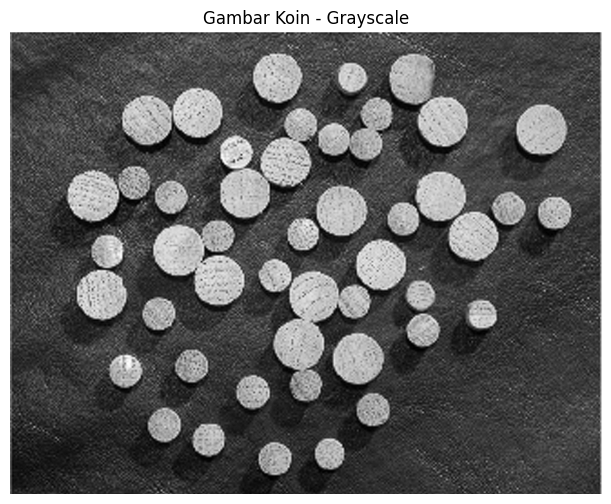

Konversi grayscale berhasil dilakukan!


In [ ]:
def rgb_to_grayscale(image):
    """
    Mengonversi citra RGB menjadi citra grayscale
    menggunakan rumus pembobotan luminansi.

    Parameter:
        image: Citra RGB dalam bentuk array NumPy.

    Mengembalikan:
        Citra grayscale dengan tipe data uint8.
    """

    image = image.astype(np.float64)

    gray = (
        0.299 * image[:, :, 0] +
        0.587 * image[:, :, 1] +
        0.114 * image[:, :, 2]
    )

    return np.clip(gray, 0, 255).astype(np.uint8)


# Mengonversi gambar koin menjadi grayscale
coins_gray = rgb_to_grayscale(coins_rgb)

# Menampilkan gambar grayscale
plt.figure(figsize=(8, 6))
plt.imshow(coins_gray, cmap='gray')
plt.title('Gambar Koin - Grayscale')
plt.axis('off')

plt.savefig(
    '/content/results/coins/02_grayscale.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

print("Konversi grayscale berhasil dilakukan!")

## 3. Segmentasi Citra Menggunakan Otsu Thresholding
Otsu Thresholding secara otomatis menentukan nilai ambang batas optimal untuk memisahkan objek foreground dan background berdasarkan distribusi intensitas piksel dan membaginya menjadi dua kelompok:

- **Background:** Piksel dengan nilai intensitas kurang dari atau sama dengan nilai threshold.
- **Foreground:** Piksel dengan nilai intensitas lebih besar dari nilai threshold.

Otsu memilih nilai threshold yang menghasilkan variansi antarkelas (between-class variance) maksimum.

### Dasar Perhitungan Matematis
Histogram citra digunakan untuk menghitung probabilitas setiap tingkat intensitas.

Bobot masing-masing kelas dihitung menggunakan:

$$w_0(t) = \sum_{i=0}^{t} p(i)$$  
$$w_1(t) = \sum_{i=t+1}^{255} p(i)$$

Rata-rata intensitas setiap kelas dihitung menggunakan:

$$\mu_0(t) = \frac{\sum_{i=0}^{t} i p(i)}{w_0(t)}$$  
$$\mu_1(t) = \frac{\sum_{i=t+1}^{255} i p(i)}{w_1(t)}$$

Variansi antarkelas dihitung menggunakan:

$$\sigma_B^2(t) = w_0(t)w_1(t) [\mu_0(t)-\mu_1(t)]^2$$

In [ ]:
def calculate_histogram(image):
    """
    Menghitung histogram citra grayscale secara manual.

    Parameter:
        image: Citra grayscale.

    Mengembalikan:
        Histogram yang berisi frekuensi 256 tingkat intensitas.
    """

    histogram = np.zeros(256, dtype=np.int64)

    for intensity in image.flatten():
        histogram[int(intensity)] += 1

    return histogram


def otsu_threshold(image):
    """
    Mengimplementasikan metode Otsu Thresholding dari awal.

    Parameter:
        image: Citra grayscale dalam bentuk array NumPy.

    Mengembalikan:
        optimal_threshold: Nilai threshold optimal.
        binary_image: Hasil segmentasi citra biner.
        histogram: Histogram citra.
        variances: Variansi antarkelas untuk setiap threshold.
    """

    histogram = calculate_histogram(image)

    total_pixels = image.size
    total_intensity = np.sum(
        np.arange(256) * histogram
    )

    weight_background = 0
    sum_background = 0

    max_variance = -1
    optimal_threshold = 0

    variances = np.zeros(256, dtype=np.float64)

    for t in range(256):

        weight_background += histogram[t]
        sum_background += t * histogram[t]

        weight_foreground = total_pixels - weight_background

        if weight_background == 0 or weight_foreground == 0:
            continue

        mean_background = (
            sum_background / weight_background
        )

        mean_foreground = (
            (total_intensity - sum_background) /
            weight_foreground
        )

        between_class_variance = (
            weight_background *
            weight_foreground *
            (mean_background - mean_foreground) ** 2
        )

        variances[t] = between_class_variance

        if between_class_variance > max_variance:
            max_variance = between_class_variance
            optimal_threshold = t

    # Membuat citra hasil segmentasi biner
    binary_image = (
        image > optimal_threshold
    ).astype(np.uint8)

    return (
        optimal_threshold,
        binary_image,
        histogram,
        variances
    )


# Menerapkan Otsu Thresholding
threshold, coins_binary, histogram, variances = otsu_threshold(
    coins_gray
)

print("Nilai threshold optimal Otsu:", threshold)

print(
    "Jumlah piksel foreground:",
    np.sum(coins_binary)
)

print(
    "Jumlah piksel background:",
    coins_binary.size - np.sum(coins_binary)
)

Nilai threshold optimal Otsu: 120
Jumlah piksel foreground: 135197
Jumlah piksel background: 465548


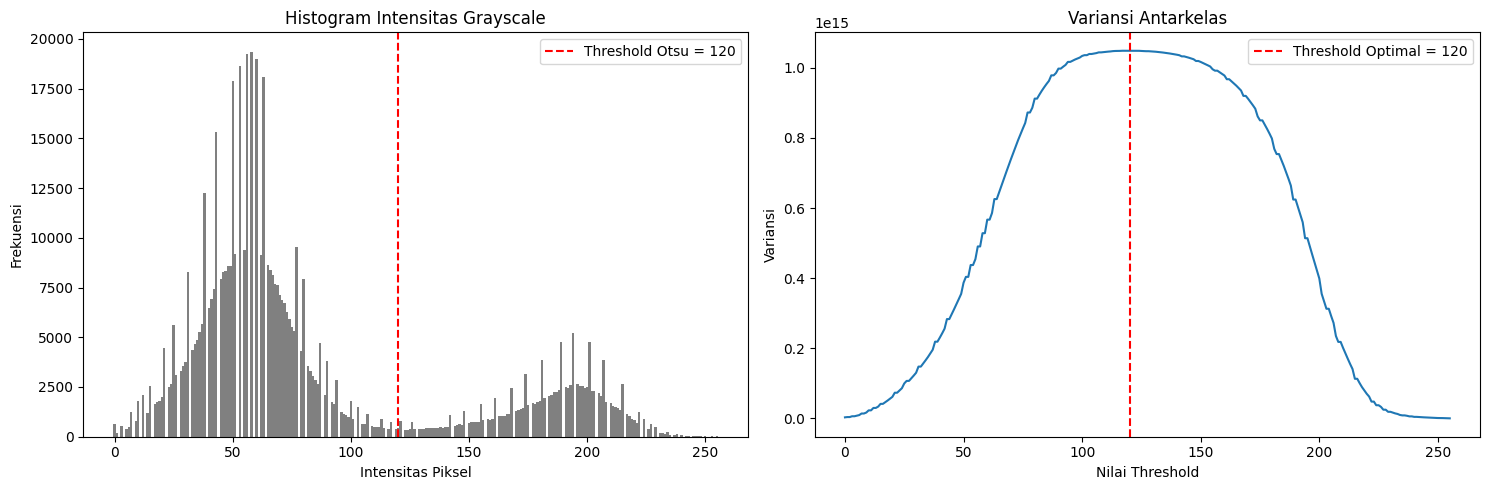

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Menampilkan histogram citra
axes[0].bar(
    np.arange(256),
    histogram,
    width=1.0,
    color='gray'
)

axes[0].axvline(
    threshold,
    color='red',
    linestyle='--',
    label=f'Threshold Otsu = {threshold}'
)

axes[0].set_title('Histogram Intensitas Grayscale')
axes[0].set_xlabel('Intensitas Piksel')
axes[0].set_ylabel('Frekuensi')
axes[0].legend()

# Menampilkan variansi antarkelas
axes[1].plot(
    np.arange(256),
    variances
)

axes[1].axvline(
    threshold,
    color='red',
    linestyle='--',
    label=f'Threshold Optimal = {threshold}'
)

axes[1].set_title('Variansi Antarkelas')
axes[1].set_xlabel('Nilai Threshold')
axes[1].set_ylabel('Variansi')
axes[1].legend()

plt.tight_layout()

plt.savefig(
    '/content/results/coins/03_otsu_histogram.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

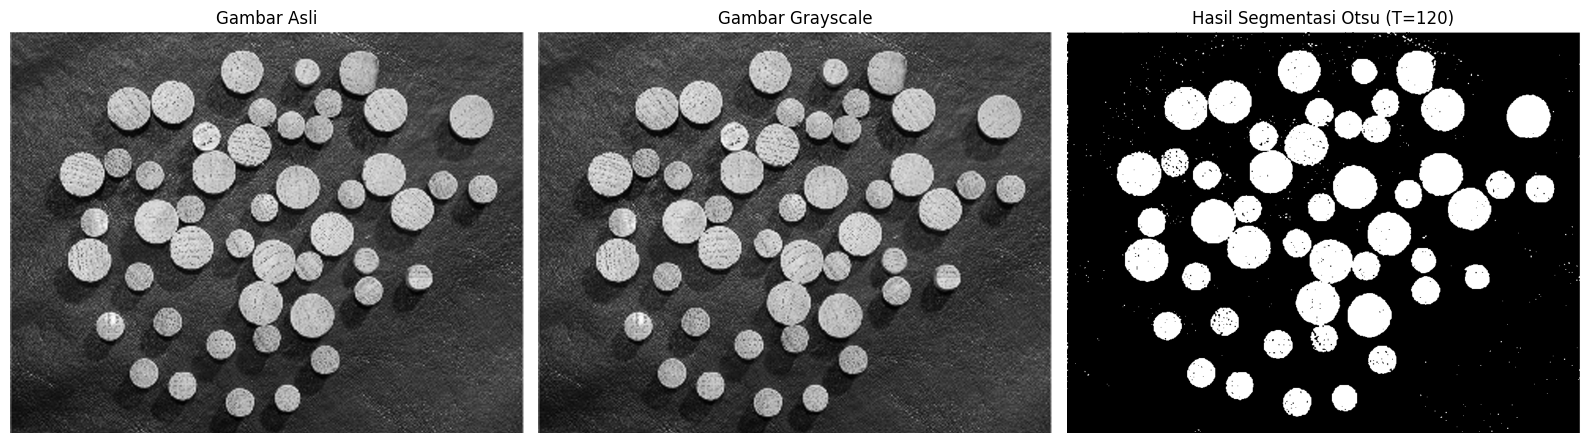

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(coins_rgb)
axes[0].set_title('Gambar Asli')
axes[0].axis('off')

axes[1].imshow(coins_gray, cmap='gray')
axes[1].set_title('Gambar Grayscale')
axes[1].axis('off')

axes[2].imshow(
    coins_binary,
    cmap='gray',
    vmin=0,
    vmax=1
)
axes[2].set_title(f'Hasil Segmentasi Otsu (T={threshold})')
axes[2].axis('off')

plt.tight_layout()

plt.savefig(
    '/content/results/coins/03_otsu_segmentation.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

## 4. Pengolahan Morfologi (Morphological Processing)
Operasi morfologi menggunakan elemen penstruktur berupa matriks yang menentukan area tetangga yang diperiksa ketika memproses setiap piksel.

Pada eksperimen ini digunakan elemen penstruktur berbentuk persegi dengan ukuran 3 × 3.

### Elemen Penstruktur
$$
B =
\begin{bmatrix}
1 & 1 & 1 \\
1 & 1 & 1 \\
1 & 1 & 1
\end{bmatrix}
$$

### 4.1 Dilation (Dilasi)
Dilasi merupakan operasi yang memperluas area foreground. Sebuah piksel akan menjadi foreground apabila setidaknya terdapat satu piksel foreground yang sesuai dengan posisi elemen penstruktur.

Dilasi dapat digunakan untuk:
- Memperbesar batas objek.
- Menghubungkan area foreground yang berdekatan.
- Mengisi celah kecil di antara objek.

### 4.2 Erosion (Erosi)
Erosi merupakan operasi yang memperkecil area foreground. Sebuah piksel hanya akan tetap menjadi foreground apabila seluruh posisi elemen penstruktur yang aktif berimpit dengan piksel foreground.

Erosi dapat digunakan untuk:
- Memperkecil batas objek.
- Menghilangkan noise foreground berukuran kecil.
- Memisahkan objek yang saling terhubung.

### 4.3 Opening (Pembukaan)
Opening merupakan kombinasi erosi yang dilanjutkan dengan dilasi untuk menghilangkan noise foreground berukuran kecil dan mempertahankan bentuk umum objek yang lebih besar.

$$A \circ B = (A \ominus B) \oplus B$$

### 4.4 Closing (Penutupan)
Closing merupakan kombinasi dilasi yang dilanjutkan dengan erosi untuk mengisi lubang kecil dan menutup celah pada area foreground.

$$A \bullet B = (A \oplus B) \ominus B$$

Elemen Penstruktur:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


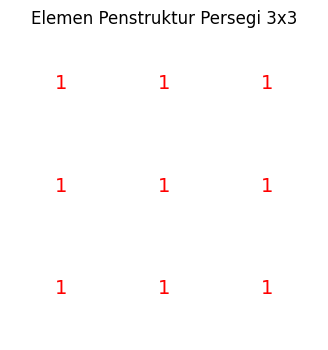

In [ ]:
# Mendefinisikan elemen penstruktur persegi berukuran 3x3
kernel = np.ones((3, 3), dtype=np.uint8)

print("Elemen Penstruktur:")
print(kernel)

plt.figure(figsize=(4, 4))
plt.imshow(kernel, cmap='gray', vmin=0, vmax=1)

for i in range(kernel.shape[0]):
    for j in range(kernel.shape[1]):
        plt.text(
            j, i, str(kernel[i, j]),
            ha='center',
            va='center',
            color='red',
            fontsize=14
        )

plt.title('Elemen Penstruktur Persegi 3x3')
plt.axis('off')
plt.show()

In [ ]:
def dilation(binary_image, kernel):
    """
    Mengimplementasikan operasi dilasi secara manual.

    Sebuah piksel menjadi foreground apabila setidaknya
    terdapat satu piksel foreground pada area elemen penstruktur.

    Parameter:
        binary_image: Citra biner yang berisi nilai 0 dan 1.
        kernel: Elemen penstruktur biner.

    Mengembalikan:
        Citra biner hasil dilasi.
    """

    image = (binary_image > 0).astype(np.uint8)

    kh, kw = kernel.shape

    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=0
    )

    output = np.zeros_like(image)

    for y in range(image.shape[0]):
        for x in range(image.shape[1]):

            region = padded[
                y:y + kh,
                x:x + kw
            ]

            # Minimal satu piksel pada area kernel
            # harus merupakan foreground
            if np.any(region[kernel == 1] == 1):
                output[y, x] = 1

    return output


# Menerapkan dilasi pada hasil segmentasi gambar koin
coins_dilated = dilation(coins_binary, kernel)

print("Operasi dilasi berhasil dilakukan!")

Operasi dilasi berhasil dilakukan!


In [ ]:
def erosion(binary_image, kernel):
    """
    Mengimplementasikan operasi erosi secara manual.

    Sebuah piksel tetap menjadi foreground hanya apabila
    seluruh posisi kernel yang aktif merupakan foreground.

    Parameter:
        binary_image: Citra biner yang berisi nilai 0 dan 1.
        kernel: Elemen penstruktur biner.

    Mengembalikan:
        Citra biner hasil erosi.
    """

    image = (binary_image > 0).astype(np.uint8)

    kh, kw = kernel.shape

    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=0
    )

    output = np.zeros_like(image)

    for y in range(image.shape[0]):
        for x in range(image.shape[1]):

            region = padded[
                y:y + kh,
                x:x + kw
            ]

            # Seluruh piksel pada posisi kernel aktif
            # harus merupakan foreground
            if np.all(region[kernel == 1] == 1):
                output[y, x] = 1

    return output


# Menerapkan erosi pada hasil segmentasi gambar koin
coins_eroded = erosion(coins_binary, kernel)

print("Operasi erosi berhasil dilakukan!")

Operasi erosi berhasil dilakukan!


In [ ]:
def opening(binary_image, kernel):
    """
    Mengimplementasikan operasi opening.

    Opening = Erosi yang dilanjutkan dengan Dilasi.
    """

    eroded = erosion(binary_image, kernel)
    opened = dilation(eroded, kernel)

    return opened


# Menerapkan opening pada hasil segmentasi gambar koin
coins_opened = opening(coins_binary, kernel)

print("Operasi opening berhasil dilakukan!")

Operasi opening berhasil dilakukan!


In [ ]:
def closing(binary_image, kernel):
    """
    Mengimplementasikan operasi closing.

    Closing = Dilasi yang dilanjutkan dengan Erosi.
    """

    dilated = dilation(binary_image, kernel)
    closed = erosion(dilated, kernel)

    return closed


# Menerapkan closing pada hasil segmentasi gambar koin
coins_closed = closing(coins_binary, kernel)

print("Operasi closing berhasil dilakukan!")

Operasi closing berhasil dilakukan!


## 5. Penerapan Operasi Morfologi
Hasil yang akan dibandingkan meliputi:

1. Hasil segmentasi awal (tanpa pengolahan morfologi).
2. Hasil operasi dilasi.
3. Hasil operasi erosi.
4. Hasil operasi opening.
5. Hasil operasi closing.

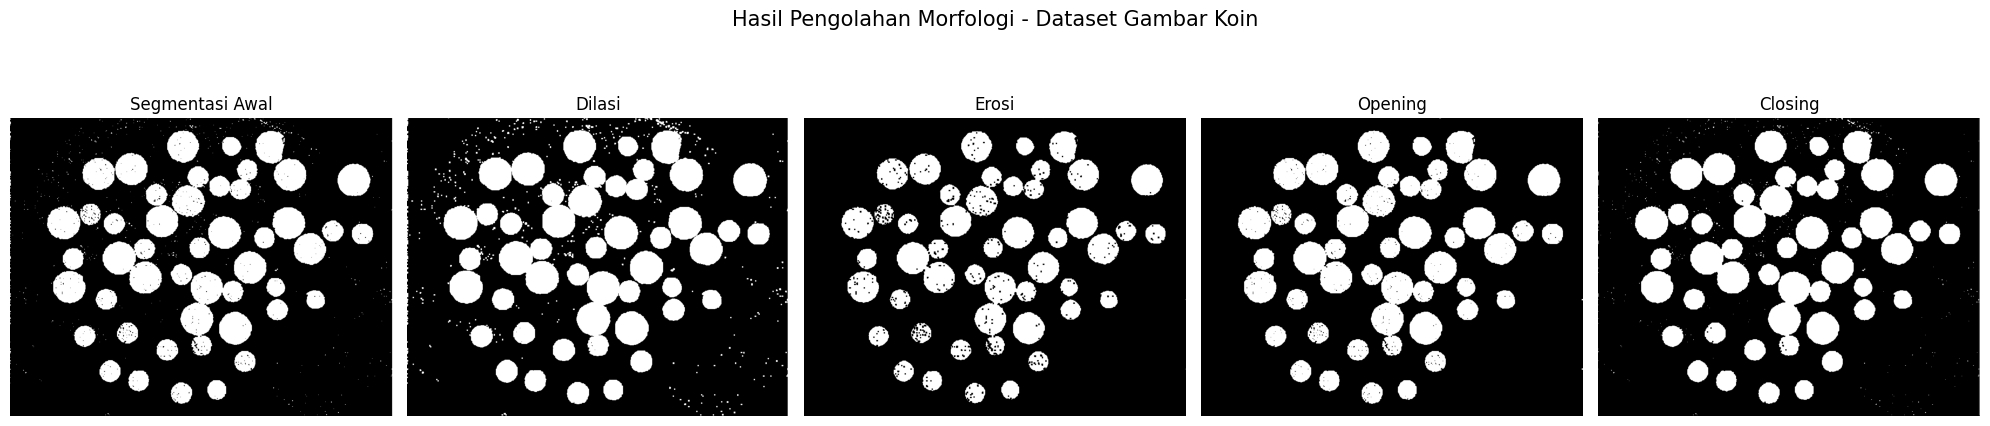

In [ ]:
# Menyimpan seluruh hasil operasi morfologi gambar koin
coins_results = {
    'Segmentasi Awal': coins_binary,
    'Dilasi': coins_dilated,
    'Erosi': coins_eroded,
    'Opening': coins_opened,
    'Closing': coins_closed
}

# Menampilkan seluruh hasil
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (title, result) in zip(axes, coins_results.items()):
    ax.imshow(result, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle(
    'Hasil Pengolahan Morfologi - Dataset Gambar Koin',
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    '/content/results/coins/04_morphological_results.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

## 6. Pengolahan Morfologi pada Gambar Objek Biner
Gambar akan dikonversi menjadi binary mask menggunakan nilai ambang batas intensitas 128.

Selanjutnya, keempat operasi morfologi (dilasi, erosi, opening, closing) diterapkan.

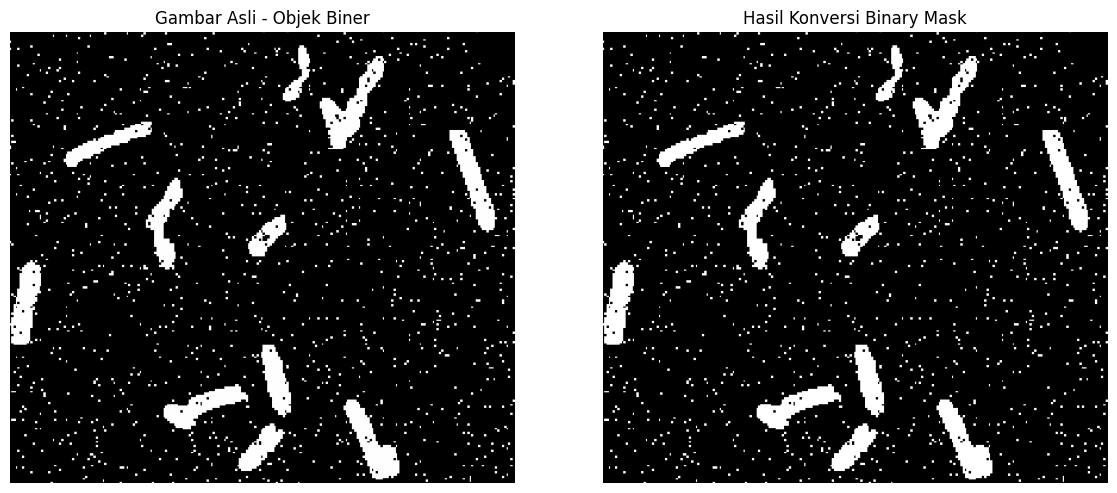

Binary mask berhasil dibuat!


In [ ]:
# Mengonversi gambar RGB menjadi grayscale
binary_gray = rgb_to_grayscale(binary_rgb)

# Mengonversi grayscale menjadi binary mask
binary_mask = (
    binary_gray >= 128
).astype(np.uint8)

# Menampilkan gambar asli dan binary mask
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary_rgb)
axes[0].set_title('Gambar Asli - Objek Biner')
axes[0].axis('off')

axes[1].imshow(
    binary_mask,
    cmap='gray',
    vmin=0,
    vmax=1
)
axes[1].set_title('Hasil Konversi Binary Mask')
axes[1].axis('off')

plt.tight_layout()

plt.savefig(
    '/content/results/binary_objects/01_binary_mask.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

print("Binary mask berhasil dibuat!")

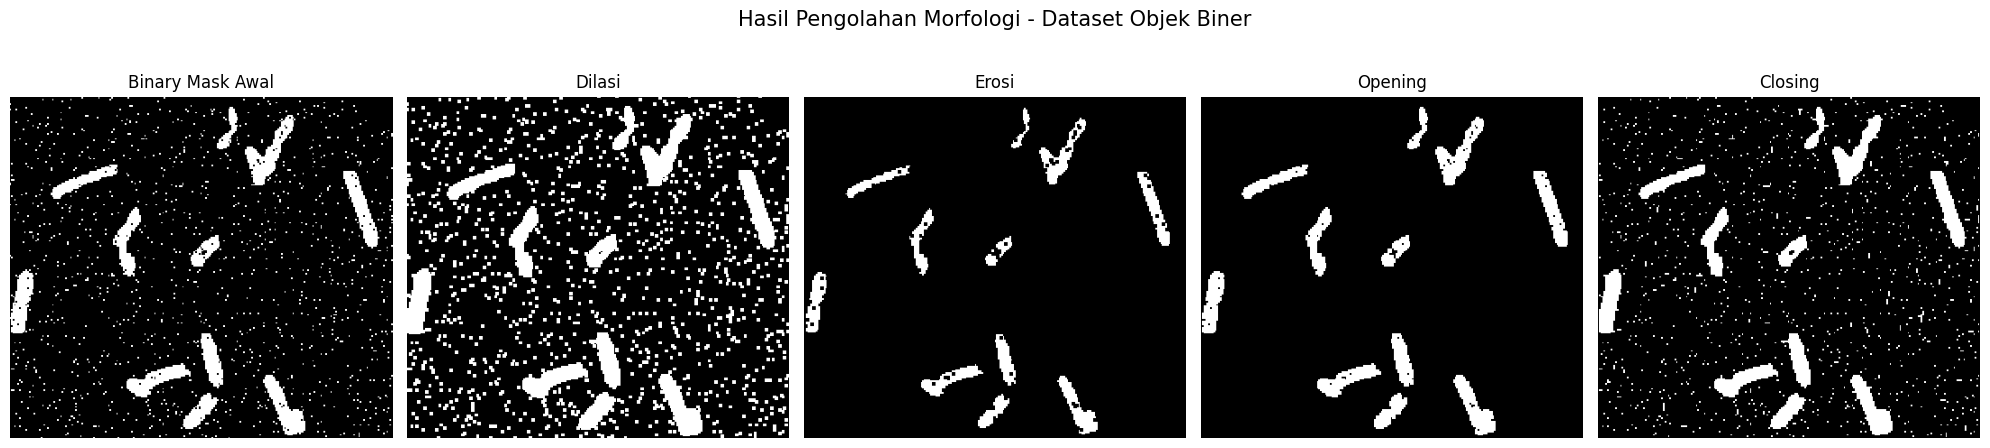

In [ ]:
# Menerapkan empat operasi morfologi
binary_dilated = dilation(binary_mask, kernel)
binary_eroded = erosion(binary_mask, kernel)
binary_opened = opening(binary_mask, kernel)
binary_closed = closing(binary_mask, kernel)

# Menyimpan seluruh hasil operasi
binary_results = {
    'Binary Mask Awal': binary_mask,
    'Dilasi': binary_dilated,
    'Erosi': binary_eroded,
    'Opening': binary_opened,
    'Closing': binary_closed
}

# Menampilkan seluruh hasil
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, (title, result) in zip(axes, binary_results.items()):
    ax.imshow(result, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')

plt.suptitle(
    'Hasil Pengolahan Morfologi - Dataset Objek Biner',
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    '/content/results/binary_objects/02_morphological_results.png',
    bbox_inches='tight',
    dpi=150
)

plt.show()

## 7. Perbandingan Hasil Segmentasi
### 7.1 Perbandingan Visual

Hasil segmentasi awal dibandingkan dengan hasil operasi dilasi, erosi, opening, dan closing.

Beberapa aspek yang diamati meliputi:
- Perubahan ukuran area foreground.
- Penghilangan noise berukuran kecil.
- Perubahan batas dan bentuk objek.
- Pengisian lubang serta celah kecil.
- Kemampuan mempertahankan struktur objek asli.

### 7.2 Perbandingan Kuantitatif
Perbandingan kuantitatif dilakukan dengan menghitung jumlah piksel foreground, background, dan persentase foreground pada setiap hasil pengolahan.

Persentase foreground dihitung menggunakan rumus:
$$Persentase\ Foreground = \frac{N_{foreground}}{N_{total}}\times 100\%$$

- $(N_{foreground})$ merupakan jumlah piksel berwarna putih.
- $(N_{total})$ merupakan jumlah seluruh piksel dalam citra.

Persentase foreground yang lebih besar tidak selalu menunjukkan hasil segmentasi yang lebih baik karena setiap operasi morfologi memiliki tujuan yang berbeda.

In [ ]:
def calculate_metrics(binary_image):
    """
    Menghitung pengukuran kuantitatif pada citra biner.
    """

    total_pixels = binary_image.size

    foreground_pixels = int(
        np.sum(binary_image == 1)
    )

    background_pixels = (
        total_pixels - foreground_pixels
    )

    foreground_percentage = (
        foreground_pixels / total_pixels
    ) * 100

    return {
        'Total Piksel': total_pixels,
        'Piksel Foreground': foreground_pixels,
        'Piksel Background': background_pixels,
        'Persentase Foreground (%)': round(
            foreground_percentage, 2
        )
    }


def create_comparison_table(results):
    """
    Membuat tabel perbandingan kuantitatif
    berdasarkan seluruh hasil operasi morfologi.
    """

    data = []

    for operation, image in results.items():

        metrics = calculate_metrics(image)

        data.append({
            'Operasi': operation,
            **metrics
        })

    return pd.DataFrame(data)


# Analisis dataset gambar koin
coins_metrics = create_comparison_table(
    coins_results
)

print("DATASET GAMBAR KOIN")
display(coins_metrics)

# Analisis dataset gambar objek biner
binary_metrics = create_comparison_table(
    binary_results
)

print("DATASET GAMBAR OBJEK BINER")
display(binary_metrics)

DATASET GAMBAR KOIN


,Operasi,Total Piksel,Piksel Foreground,Piksel Background,Persentase Foreground (%)
0,Segmentasi Awal,600745,135197,465548,22.50
1,Dilasi,600745,154120,446625,25.65
2,Erosi,600745,116354,484391,19.37
3,Opening,600745,131404,469341,21.87
4,Closing,600745,134876,465869,22.45


DATASET GAMBAR OBJEK BINER


,Operasi,Total Piksel,Piksel Foreground,Piksel Background,Persentase Foreground (%)
0,Binary Mask Awal,160696,14511,146185,9.03
1,Dilasi,160696,29201,131495,18.17
2,Erosi,160696,7744,152952,4.82
3,Opening,160696,10438,150258,6.50
4,Closing,160696,15050,145646,9.37


In [ ]:
def save_binary_image(image, filepath):
    """
    Menyimpan citra biner NumPy ke dalam format PNG.
    """

    output = (image * 255).astype(np.uint8)
    Image.fromarray(output).save(filepath)


# Menyimpan hasil pengolahan gambar koin
coins_output_dir = '/content/results/coins'

save_binary_image(
    coins_binary,
    f'{coins_output_dir}/03_otsu_segmentation.png'
)

save_binary_image(
    coins_dilated,
    f'{coins_output_dir}/04_dilation.png'
)

save_binary_image(
    coins_eroded,
    f'{coins_output_dir}/05_erosion.png'
)

save_binary_image(
    coins_opened,
    f'{coins_output_dir}/06_opening.png'
)

save_binary_image(
    coins_closed,
    f'{coins_output_dir}/07_closing.png'
)

# Menyimpan hasil pengolahan gambar objek biner
binary_output_dir = '/content/results/binary_objects'

save_binary_image(
    binary_mask,
    f'{binary_output_dir}/01_original.png'
)

save_binary_image(
    binary_dilated,
    f'{binary_output_dir}/02_dilation.png'
)

save_binary_image(
    binary_eroded,
    f'{binary_output_dir}/03_erosion.png'
)

save_binary_image(
    binary_opened,
    f'{binary_output_dir}/04_opening.png'
)

save_binary_image(
    binary_closed,
    f'{binary_output_dir}/05_closing.png'
)

print("Seluruh hasil gambar berhasil disimpan!")

Seluruh hasil gambar berhasil disimpan!
